In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset loaded successfully")
print("Number of records:", len(df))
print("Number of attributes:", len(df.columns))

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Saving Rajasthan_Heatwave_2006_2025.csv to Rajasthan_Heatwave_2006_2025.csv
Dataset loaded successfully
Number of records: 21960
Number of attributes: 23

Columns:
['YEAR', 'MONTH', 'DAY', 'WIND_U10', 'WIND_V10', 'MSLP', 'BLH', 'GEOP', 'TEMP2M', 'TMAX', 'TMIN', 'DEW2M', 'CLOUD', 'RAIN', 'SRAD', 'EVAP', 'SOILT1', 'SOILM1', 'LAI', 'HEATWAVE', 'LAT', 'LON', 'DISTRICT']

First 5 rows:
   YEAR  MONTH  DAY  WIND_U10  WIND_V10        MSLP        BLH       GEOP  \
0  2006      3    1 -0.223022 -0.440903  101036.375  2020.7317  1671.1079   
1  2006      3    2 -1.344009 -0.294922  101076.440  2265.7910  1671.1079   
2  2006      3    3 -0.960449  1.522965  101033.750  3152.6023  1671.1079   
3  2006      3    4  2.704514  1.733017  100896.940  3146.9475  1671.1079   
4  2006      3    5  2.717834  2.464432  101014.190  2069.5261  1671.1079   

      TEMP2M       TMAX  ...  RAIN     SRAD      EVAP     SOILT1    SOILM1  \
0  304.75806  303.54395  ...   0.0  3117056 -0.000023  312.75903  0.024887 

### Theory

Data preprocessing is an important step in data analysis and machine learning. It converts raw data into a clean and suitable form for further analysis.

1. Skewness:
Skewness measures the asymmetry of a dataset. Positive skewness indicates right-skewed data, while negative skewness indicates left-skewed data.

2. Histogram:
A histogram represents the distribution of numerical data using bars. It helps to understand the shape and spread of the data and identify skewness.

3. KDE Plot:
Kernel Density Estimation (KDE) is used to show the probability distribution of numerical data in a smooth curve.

4. Min-Max Scaling:
Min-Max scaling transforms numerical values into a fixed range, usually 0 to 1. It is useful when features have different ranges.

5. Z-Score Standardization:
Z-score standardization transforms data using its mean and standard deviation. The resulting data has a mean close to 0 and a standard deviation close to 1.

6. Categorical Encoding:
Categorical encoding converts categorical data such as district names into numerical values so that it can be processed by machine learning algorithms.

7. One-Hot Encoding:
One-hot encoding creates separate columns for different categories. Each category is represented using binary values.

8. Dummy Variable Trap:
The dummy variable trap occurs when redundant dummy variables are included in a model. Removing one dummy variable helps avoid this problem.

In [2]:
print("Missing values in each attribute:\n")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each attribute:

YEAR        0
MONTH       0
DAY         0
WIND_U10    0
WIND_V10    0
MSLP        0
BLH         0
GEOP        0
TEMP2M      0
TMAX        0
TMIN        0
DEW2M       0
CLOUD       0
RAIN        0
SRAD        0
EVAP        0
SOILT1      0
SOILM1      0
LAI         0
HEATWAVE    0
LAT         0
LON         0
DISTRICT    0
dtype: int64

Total missing values: 0


In [3]:
tmax = df["TMAX"].dropna()

skewness = tmax.skew()

print("Skewness of TMAX =", skewness)

if skewness > 0:
    print("The data is positively skewed (right-skewed).")
elif skewness < 0:
    print("The data is negatively skewed (left-skewed).")
else:
    print("The data is approximately symmetric.")


Skewness of TMAX = -0.8046303564433371
The data is negatively skewed (left-skewed).


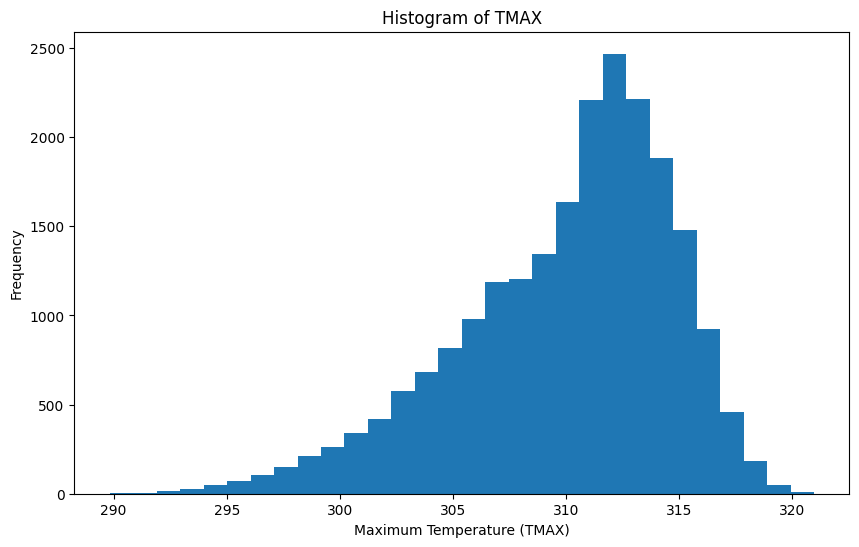

In [4]:
plt.figure(figsize=(10,6))

plt.hist(df["TMAX"].dropna(), bins=30)

plt.xlabel("Maximum Temperature (TMAX)")
plt.ylabel("Frequency")
plt.title("Histogram of TMAX")

plt.show()

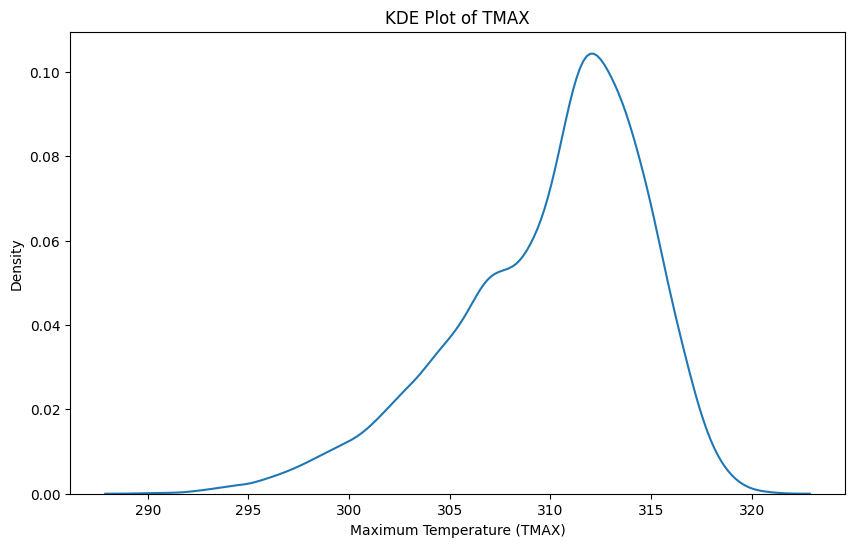

In [5]:
plt.figure(figsize=(10,6))

sns.kdeplot(df["TMAX"].dropna())

plt.xlabel("Maximum Temperature (TMAX)")
plt.ylabel("Density")
plt.title("KDE Plot of TMAX")

plt.show()

In [6]:
tmax = df["TMAX"].dropna()

minimum = tmax.min()
maximum = tmax.max()

tmax_minmax = (tmax - minimum) / (maximum - minimum)

print("Minimum TMAX =", minimum)
print("Maximum TMAX =", maximum)

print("\nFirst 10 Min-Max scaled values:")
print(tmax_minmax.head(10))

Minimum TMAX = 289.82178
Maximum TMAX = 320.95996

First 10 Min-Max scaled values:
0    0.440686
1    0.486067
2    0.526360
3    0.542206
4    0.483692
5    0.483276
6    0.509495
7    0.508687
8    0.401272
9    0.244092
Name: TMAX, dtype: float64


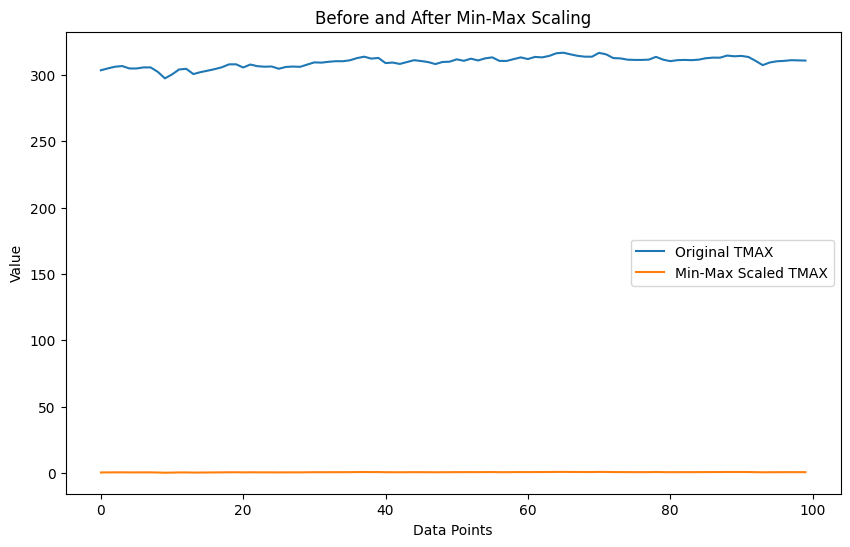

In [7]:
plt.figure(figsize=(10,6))

plt.plot(tmax.head(100), label="Original TMAX")
plt.plot(tmax_minmax.head(100), label="Min-Max Scaled TMAX")

plt.xlabel("Data Points")
plt.ylabel("Value")
plt.title("Before and After Min-Max Scaling")
plt.legend()

plt.show()

In [8]:
tmax = df["TMAX"].dropna()

mean = tmax.mean()
std = tmax.std()

tmax_zscore = (tmax - mean) / std

print("Mean =", mean)
print("Standard Deviation =", std)

print("\nFirst 10 Z-score standardized values:")
print(tmax_zscore.head(10))

Mean = 310.01270390847
Standard Deviation = 4.749862243520171

First 10 Z-score standardized values:
0   -1.361882
1   -1.064383
2   -0.800241
3   -0.696362
4   -1.079956
5   -1.082681
6   -0.910802
7   -0.916095
8   -1.620269
9   -2.650676
Name: TMAX, dtype: float64


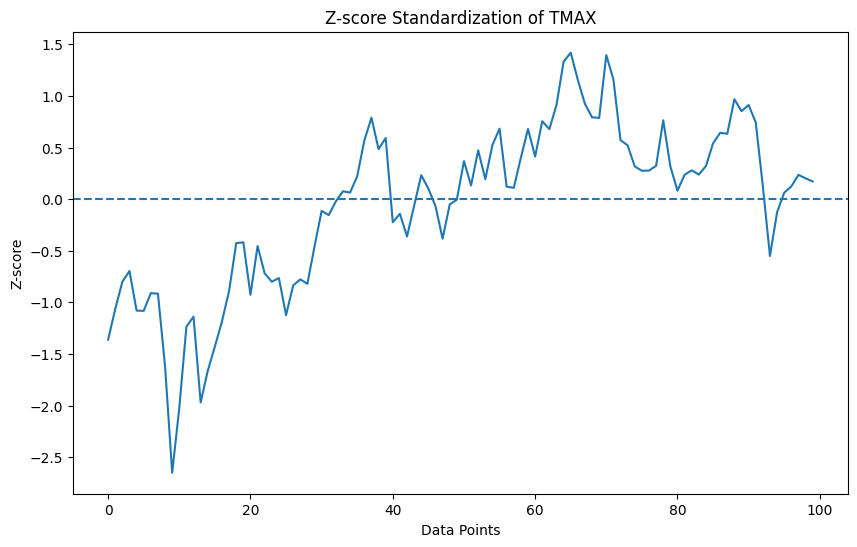

In [9]:
plt.figure(figsize=(10,6))

plt.plot(tmax_zscore.head(100))

plt.xlabel("Data Points")
plt.ylabel("Z-score")
plt.title("Z-score Standardization of TMAX")

plt.axhline(0, linestyle="--")

plt.show()

In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["DISTRICT_ENCODED"] = le.fit_transform(df["DISTRICT"].astype(str))

print("Categorical Encoding of DISTRICT")
print(df[["DISTRICT", "DISTRICT_ENCODED"]].head(10))

Categorical Encoding of DISTRICT
  DISTRICT  DISTRICT_ENCODED
0   Barmer                 0
1   Barmer                 0
2   Barmer                 0
3   Barmer                 0
4   Barmer                 0
5   Barmer                 0
6   Barmer                 0
7   Barmer                 0
8   Barmer                 0
9   Barmer                 0


In [11]:
district_onehot = pd.get_dummies(df["DISTRICT"], prefix="DISTRICT")

print("One-Hot Encoded Districts:")
print(district_onehot.head())

One-Hot Encoded Districts:
   DISTRICT_Barmer  DISTRICT_Bikaner  DISTRICT_Churu  DISTRICT_Jaipur  \
0             True             False           False            False   
1             True             False           False            False   
2             True             False           False            False   
3             True             False           False            False   
4             True             False           False            False   

   DISTRICT_Jaisalmer  DISTRICT_Jodhpur  DISTRICT_Kota  DISTRICT_Nagaur  \
0               False             False          False            False   
1               False             False          False            False   
2               False             False          False            False   
3               False             False          False            False   
4               False             False          False            False   

   DISTRICT_Sri Ganganagar  
0                    False  
1                    Fals

In [12]:
district_dummy = pd.get_dummies(df["DISTRICT"], prefix="DISTRICT", drop_first=True)

print("Dummy Variables after removing first category:")
print(district_dummy.head())

Dummy Variables after removing first category:
   DISTRICT_Bikaner  DISTRICT_Churu  DISTRICT_Jaipur  DISTRICT_Jaisalmer  \
0             False           False            False               False   
1             False           False            False               False   
2             False           False            False               False   
3             False           False            False               False   
4             False           False            False               False   

   DISTRICT_Jodhpur  DISTRICT_Kota  DISTRICT_Nagaur  DISTRICT_Sri Ganganagar  
0             False          False            False                    False  
1             False          False            False                    False  
2             False          False            False                    False  
3             False          False            False                    False  
4             False          False            False                    False  


In [13]:
print("Original number of columns:", len(df.columns))

print("Number of one-hot encoded columns:", len(district_onehot.columns))

print("\nOne-Hot Encoded Dataset Shape:")
print(district_onehot.shape)

Original number of columns: 24
Number of one-hot encoded columns: 9

One-Hot Encoded Dataset Shape:
(21960, 9)


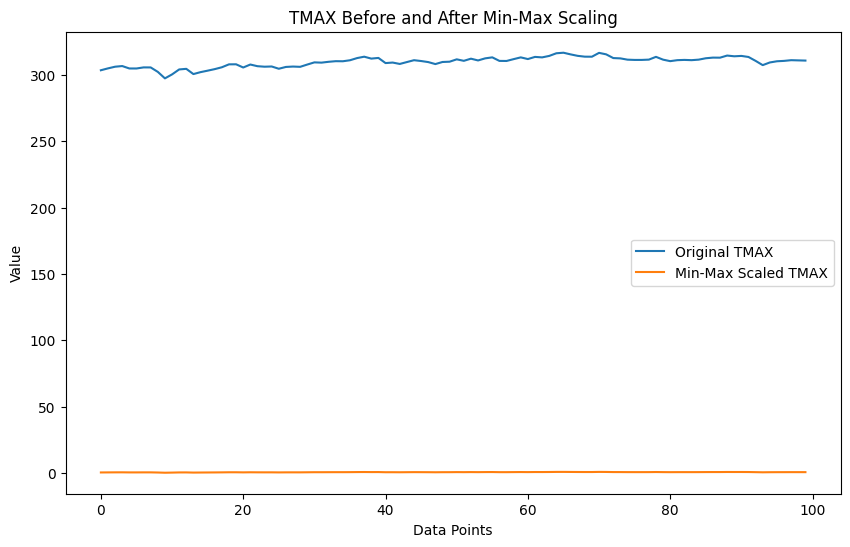

In [14]:
plt.figure(figsize=(10,6))

plt.plot(tmax.head(100), label="Original TMAX")
plt.plot(tmax_minmax.head(100), label="Min-Max Scaled TMAX")

plt.xlabel("Data Points")
plt.ylabel("Value")
plt.title("TMAX Before and After Min-Max Scaling")
plt.legend()

plt.show()

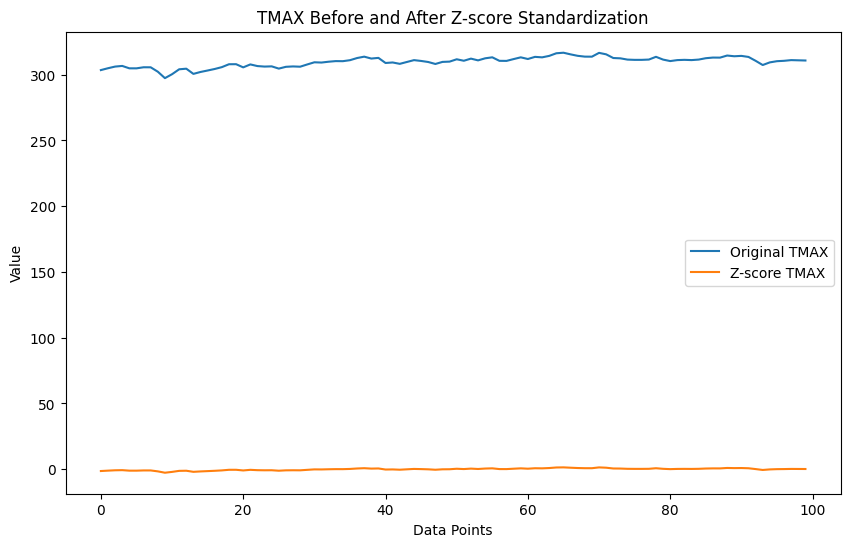

In [15]:
plt.figure(figsize=(10,6))

plt.plot(tmax.head(100), label="Original TMAX")
plt.plot(tmax_zscore.head(100), label="Z-score TMAX")

plt.xlabel("Data Points")
plt.ylabel("Value")
plt.title("TMAX Before and After Z-score Standardization")
plt.legend()

plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

tmax_scaled = scaler.fit_transform(df[["TMAX"]].dropna())

print("First 10 Scikit-Learn Min-Max scaled values:")
print(tmax_scaled[:10])

First 10 Scikit-Learn Min-Max scaled values:
[[0.44068632]
 [0.48606727]
 [0.52635992]
 [0.54220574]
 [0.48369173]
 [0.48327616]
 [0.50949477]
 [0.50868741]
 [0.40127169]
 [0.24409198]]


In [20]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

tmax_standardized = standard_scaler.fit_transform(df[["TMAX"]].dropna())

print("First 10 Scikit-Learn standardized values:")
print(tmax_standardized[:10])

First 10 Scikit-Learn standardized values:
[[-1.36191343]
 [-1.06440751]
 [-0.80025909]
 [-0.69637793]
 [-1.07998094]
 [-1.0827053 ]
 [-0.91082271]
 [-0.91611562]
 [-1.62030576]
 [-2.65073595]]


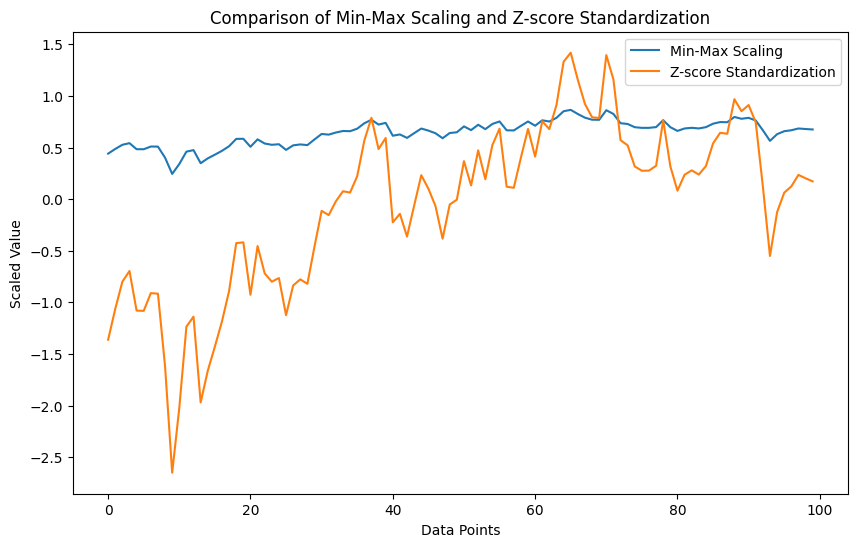

In [21]:
plt.figure(figsize=(10,6))

plt.plot(tmax_scaled[:100], label="Min-Max Scaling")
plt.plot(tmax_standardized[:100], label="Z-score Standardization")

plt.xlabel("Data Points")
plt.ylabel("Scaled Value")
plt.title("Comparison of Min-Max Scaling and Z-score Standardization")
plt.legend()

plt.show()

In [22]:
print("Final Dataset Information")
print("Number of records:", len(df))
print("Number of attributes:", len(df.columns))

print("\nFinal columns:")
print(df.columns.tolist())

Final Dataset Information
Number of records: 21960
Number of attributes: 24

Final columns:
['YEAR', 'MONTH', 'DAY', 'WIND_U10', 'WIND_V10', 'MSLP', 'BLH', 'GEOP', 'TEMP2M', 'TMAX', 'TMIN', 'DEW2M', 'CLOUD', 'RAIN', 'SRAD', 'EVAP', 'SOILT1', 'SOILM1', 'LAI', 'HEATWAVE', 'LAT', 'LON', 'DISTRICT', 'DISTRICT_ENCODED']


### Conclusion

The Rajasthan Heatwave dataset was analyzed using skewness, histogram, and KDE plots. Min-Max normalization and Z-score standardization were performed on the TMAX attribute. Categorical encoding techniques were also applied to the DISTRICT attribute. These preprocessing techniques help prepare the dataset for further data analysis and machine learning.
